<a href="https://colab.research.google.com/github/joshnimal08-cell/diabetes-analysis/blob/main/diabetes_biostats_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
import pandas as pd

demo = pd.read_sas("https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_DEMO.xpt")
diq = pd.read_sas("https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_DIQ.xpt")

print(demo.shape)
print(diq.shape)
demo.head()

(15560, 29)
(14986, 28)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,DMDBORN4,...,FIAINTRP,MIALANG,MIAPROXY,MIAINTRP,AIALANGA,WTINTPRP,WTMECPRP,SDMVPSU,SDMVSTRA,INDFMPIR
0,109263.0,66.0,2.0,1.0,2.0,NaN,5.0,6.0,2.0,1.0,...,2.0,NaN,NaN,NaN,NaN,7891.762435,8.951816e+03,3.0,156.0,4.66
1,109264.0,66.0,2.0,2.0,13.0,NaN,1.0,1.0,2.0,1.0,...,2.0,1.0,2.0,2.0,1.0,11689.747264,1.227116e+04,1.0,155.0,0.83
2,109265.0,66.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,1.0,...,2.0,NaN,NaN,NaN,NaN,16273.825939,1.665876e+04,1.0,157.0,3.06
3,109266.0,66.0,2.0,2.0,29.0,NaN,5.0,6.0,2.0,2.0,...,2.0,1.0,2.0,2.0,1.0,7825.646112,8.154968e+03,2.0,168.0,5.00
4,109267.0,66.0,1.0,2.0,21.0,NaN,2.0,2.0,NaN,2.0,...,2.0,NaN,NaN,NaN,NaN,26379.991724,5.397605e-79,1.0,156.0,5.00


In [30]:
bmx = pd.read_sas("https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_BMX.xpt")
bpx = pd.read_sas("https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_BPXO.xpt")

print(bmx.shape)
print(bpx.shape)
bmx.head()

(14300, 22)
(11656, 12)


,SEQN,BMDSTATS,BMXWT,BMIWT,BMXRECUM,BMIRECUM,BMXHEAD,BMIHEAD,BMXHT,BMIHT,...,BMXLEG,BMILEG,BMXARML,BMIARML,BMXARMC,BMIARMC,BMXWAIST,BMIWAIST,BMXHIP,BMIHIP
0,109263.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,109264.0,1.0,42.2,NaN,NaN,NaN,NaN,NaN,154.7,NaN,...,36.3,NaN,33.8,NaN,22.7,NaN,63.8,NaN,85.0,NaN
2,109265.0,1.0,12.0,NaN,91.6,NaN,NaN,NaN,89.3,NaN,...,NaN,NaN,18.6,NaN,14.8,NaN,41.2,NaN,NaN,NaN
3,109266.0,1.0,97.1,NaN,NaN,NaN,NaN,NaN,160.2,NaN,...,40.8,NaN,34.7,NaN,35.8,NaN,117.9,NaN,126.1,NaN
4,109269.0,3.0,13.6,NaN,90.9,NaN,NaN,NaN,NaN,1.0,...,NaN,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,NaN


In [31]:
merged = pd.merge(demo, diq, on="SEQN", how="inner")
print(merged.shape)

(14986, 56)


In [32]:
merged = pd.merge(merged, bmx, on="SEQN", how="inner")
merged = pd.merge(merged, bpx, on="SEQN", how="inner")
print(merged.shape)

(11656, 88)


In [33]:
cols = ["SEQN", "RIDAGEYR", "DIQ010", "BMXBMI", "BPXOSY1", "BPXODI1"]
df = merged[cols].copy()
print(df.shape)
df.head()

(11656, 6)


,SEQN,RIDAGEYR,DIQ010,BMXBMI,BPXOSY1,BPXODI1
0,109264.0,13.0,2.0,17.6,109.0,67.0
1,109266.0,29.0,2.0,37.8,99.0,56.0
2,109270.0,11.0,2.0,30.9,123.0,73.0
3,109271.0,49.0,2.0,29.7,102.0,65.0
4,109273.0,36.0,2.0,21.9,116.0,68.0


In [34]:
df = df[df["DIQ010"].isin([1, 2])].copy()
print(df.shape)

(11380, 6)


In [35]:
df["diabetes"] = df["DIQ010"].map({1: "Yes", 2: "No"})
df["diabetes"].value_counts()

,count
diabetes,
No,10034
Yes,1346


In [36]:
df = df.rename(columns={
    "RIDAGEYR": "age",
    "BMXBMI": "bmi",
    "BPXOSY1": "systolic_bp",
    "BPXODI1": "diastolic_bp"
})
df.head()

,SEQN,age,DIQ010,bmi,systolic_bp,diastolic_bp,diabetes
0,109264.0,13.0,2.0,17.6,109.0,67.0,No
1,109266.0,29.0,2.0,37.8,99.0,56.0,No
2,109270.0,11.0,2.0,30.9,123.0,73.0,No
3,109271.0,49.0,2.0,29.7,102.0,65.0,No
4,109273.0,36.0,2.0,21.9,116.0,68.0,No


In [37]:
df = df[df["age"] >= 18].copy()
print(df.shape)

(8709, 7)


In [38]:
df[["age", "bmi", "systolic_bp", "diastolic_bp"]].describe()


,age,bmi,systolic_bp,diastolic_bp
count,8709.000000,8538.000000,7799.000000,7799.000000
mean,49.234815,29.825861,124.294397,74.788563
std,18.486164,7.554682,19.779621,11.919099
min,18.000000,14.200000,66.000000,36.000000
25%,33.000000,24.600000,110.000000,67.000000
50%,50.000000,28.600000,121.000000,74.000000
75%,64.000000,33.600000,135.000000,82.000000
max,80.000000,92.300000,225.000000,151.000000


In [39]:
df_clean = df.dropna(subset=["age", "bmi", "systolic_bp", "diastolic_bp"]).copy()
print(df_clean.shape)

(7722, 7)


In [40]:
df_clean.groupby("diabetes")[["bmi", "systolic_bp", "diastolic_bp"]].mean()

,bmi,systolic_bp,diastolic_bp
diabetes,,,
No,29.319863,122.920976,74.852021
Yes,32.780548,131.251928,74.419880


In [41]:
from scipy import stats

yes_bmi = df_clean[df_clean["diabetes"] == "Yes"]["bmi"]
no_bmi = df_clean[df_clean["diabetes"] == "No"]["bmi"]

t_stat, p_value = stats.ttest_ind(yes_bmi, no_bmi)
print("t-statistic:", t_stat)
print("p-value:", p_value)

t-statistic: 14.866102264907402
p-value: 2.6195533724222872e-49


In [42]:
yes_bp = df_clean[df_clean["diabetes"] == "Yes"]["systolic_bp"]
no_bp = df_clean[df_clean["diabetes"] == "No"]["systolic_bp"]

t_stat, p_value = stats.ttest_ind(yes_bp, no_bp)
print("t-statistic:", t_stat)
print("p-value:", p_value)


t-statistic: 13.503966283476117
p-value: 4.3280263713023535e-41


In [43]:
yes_age = df_clean[df_clean["diabetes"] == "Yes"]["age"]
no_age = df_clean[df_clean["diabetes"] == "No"]["age"]

print("Mean age (Yes):", yes_age.mean())
print("Mean age (No):", no_age.mean())

t_stat, p_value = stats.ttest_ind(yes_age, no_age)
print("t-statistic:", t_stat)
print("p-value:", p_value)

Mean age (Yes): 62.21765209940017
Mean age (No): 46.748588863463006
t-statistic: 27.90097939283903
p-value: 2.661756274915119e-163


In [44]:
paq = pd.read_sas("https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/P_PAQ.xpt")
print(paq.shape)
paq.head()

(9693, 17)


,SEQN,PAQ605,PAQ610,PAD615,PAQ620,PAQ625,PAD630,PAQ635,PAQ640,PAD645,PAQ650,PAQ655,PAD660,PAQ665,PAQ670,PAD675,PAD680
0,109266.0,2.0,NaN,NaN,2.0,NaN,NaN,2.0,NaN,NaN,1.0,5.0,60.0,1.0,4.0,30.0,480.0
1,109267.0,2.0,NaN,NaN,2.0,NaN,NaN,2.0,NaN,NaN,1.0,6.0,90.0,2.0,NaN,NaN,540.0
2,109268.0,1.0,5.0,540.0,1.0,5.0,300.0,2.0,NaN,NaN,2.0,NaN,NaN,2.0,NaN,NaN,540.0
3,109271.0,2.0,NaN,NaN,1.0,2.0,120.0,2.0,NaN,NaN,2.0,NaN,NaN,2.0,NaN,NaN,60.0
4,109273.0,1.0,3.0,240.0,2.0,NaN,NaN,2.0,NaN,NaN,2.0,NaN,NaN,1.0,4.0,120.0,180.0


In [45]:
df_clean = pd.merge(df_clean, paq[["SEQN", "PAQ665"]], on="SEQN", how="inner")
print(df_clean.shape)

(7722, 8)


In [46]:
df_clean = df_clean[df_clean["PAQ665"].isin([1, 2])].copy()
df_clean["activity"] = df_clean["PAQ665"].map({1: "Yes", 2: "No"})
print(df_clean.shape)
df_clean["activity"].value_counts()

(7720, 9)


,count
activity,
No,4502
Yes,3218


In [47]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df_clean["activity"], df_clean["diabetes"])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
print("Chi-square statistic:", chi2)
print("p-value:", p)

diabetes    No  Yes
activity           
No        3712  790
Yes       2841  377
Chi-square statistic: 49.2965138494372
p-value: 2.200532083583927e-12


In [48]:
df_clean["diabetes_num"] = df_clean["diabetes"].map({"Yes": 1, "No": 0})
df_clean["activity_num"] = df_clean["activity"].map({"Yes": 1, "No": 0})
df_clean[["diabetes", "diabetes_num", "activity", "activity_num"]].head()

,diabetes,diabetes_num,activity,activity_num
0,No,0,Yes,1
1,No,0,No,0
2,No,0,Yes,1
3,Yes,1,Yes,1
4,No,0,No,0


In [49]:
import statsmodels.formula.api as smf

model = smf.logit("diabetes_num ~ age + bmi + systolic_bp + activity_num", data=df_clean).fit()
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.358369
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:           diabetes_num   No. Observations:                 7720
Model:                          Logit   Df Residuals:                     7715
Method:                           MLE   Df Model:                            4
Date:                Sun, 18 Oct 2026   Pseudo R-squ.:                  0.1562
Time:                        22:40:50   Log-Likelihood:                -2766.6
converged:                       True   LL-Null:                       -3278.9
Covariance Type:            nonrobust   LLR p-value:                1.710e-220
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -7.1801      0.291    -24.677      0.000      -7.750      -6.610
age              0.0573

In [50]:
import numpy as np

odds_ratios = np.exp(model.params)
print(odds_ratios)

Intercept       0.000762
age             1.058958
bmi             1.071075
systolic_bp     1.001920
activity_num    0.793035
dtype: float64


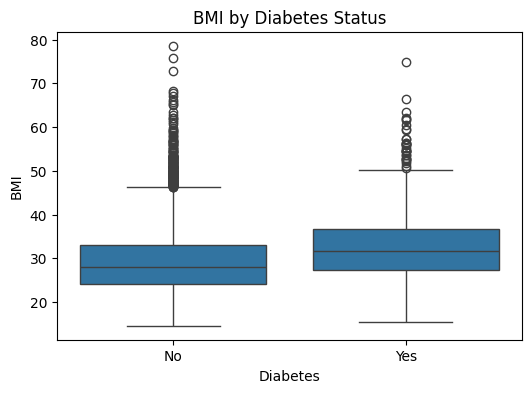

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.boxplot(data=df_clean, x="diabetes", y="bmi")
plt.title("BMI by Diabetes Status")
plt.xlabel("Diabetes")
plt.ylabel("BMI")
plt.savefig("bmi_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

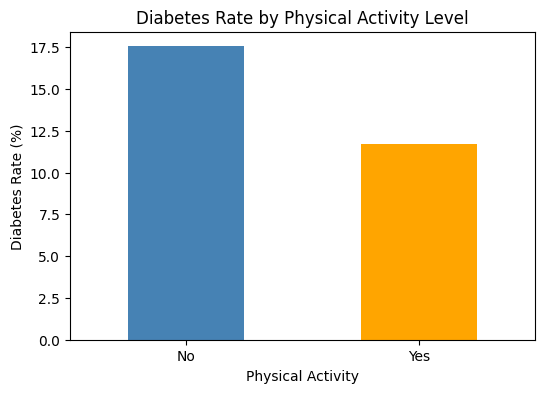

In [52]:
rates = df_clean.groupby("activity")["diabetes_num"].mean() * 100

plt.figure(figsize=(6,4))
rates.plot(kind="bar", color=["steelblue", "orange"])
plt.title("Diabetes Rate by Physical Activity Level")
plt.xlabel("Physical Activity")
plt.ylabel("Diabetes Rate (%)")
plt.xticks(rotation=0)
plt.savefig("activity_barchart.png", dpi=150, bbox_inches="tight")
plt.show()

In [53]:
n1 = len(yes_bmi)
n2 = len(no_bmi)
df = n1 + n2 - 2
print("df:", df)

df: 7720


In [54]:
print(df_clean.shape)
print(df_clean["diabetes"].value_counts())
print(df_clean["diabetes"].value_counts(normalize=True) * 100)

(7720, 11)
diabetes
No     6553
Yes    1167
Name: count, dtype: int64
diabetes
No     84.88342
Yes    15.11658
Name: proportion, dtype: float64


In [55]:
from scipy import stats

yes = df_clean[df_clean["diabetes"] == "Yes"]
no = df_clean[df_clean["diabetes"] == "No"]

for var in ["bmi", "systolic_bp", "age"]:
    t, p = stats.ttest_ind(yes[var], no[var])
    print(var, "| Yes mean:", round(yes[var].mean(), 1), "| No mean:", round(no[var].mean(), 1),
          "| t:", round(t, 2), "| p:", p, "| df:", len(yes) + len(no) - 2)

bmi | Yes mean: 32.8 | No mean: 29.3 | t: 14.87 | p: 2.550585927636497e-49 | df: 7718
systolic_bp | Yes mean: 131.3 | No mean: 122.9 | t: 13.51 | p: 4.2154141239636416e-41 | df: 7718
age | Yes mean: 62.2 | No mean: 46.7 | t: 27.92 | p: 1.672328120573209e-163 | df: 7718


In [56]:
df_clean[["age", "bmi", "systolic_bp"]].corr()

,age,bmi,systolic_bp
age,1.000000,0.039737,0.453038
bmi,0.039737,1.000000,0.039226
systolic_bp,0.453038,0.039226,1.000000
